In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

BASE_DIR = os.getcwd()

DATA_DIR = os.path.join(
    BASE_DIR,
    "data"
)

DATA_FILE = os.path.join(
    DATA_DIR,
    "wdbc.data"
)

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "outputs"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print("Libraries imported successfully.")
print("Dataset path:", DATA_FILE)

Libraries imported successfully.
Dataset path: /Users/akshitgulati/Downloads/AI IN HEALTHCARE/Lab_Experiment_4/data/wdbc.data


In [2]:
columns = [
    "id",
    "diagnosis",
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se",
    "texture_se",
    "perimeter_se",
    "area_se",
    "smoothness_se",
    "compactness_se",
    "concavity_se",
    "concave_points_se",
    "symmetry_se",
    "fractal_dimension_se",
    "radius_worst",
    "texture_worst",
    "perimeter_worst",
    "area_worst",
    "smoothness_worst",
    "compactness_worst",
    "concavity_worst",
    "concave_points_worst",
    "symmetry_worst",
    "fractal_dimension_worst"
]

df = pd.read_csv(
    DATA_FILE,
    header=None,
    names=columns
)

print("Dataset loaded successfully.")

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset loaded successfully.

First 5 rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset shape:
(569, 32)

Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Data types:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave_points_mean        float64
symmetry_mean              floa

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01



Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis distribution percentage:


diagnosis
B    62.74
M    37.26
Name: Percentage, dtype: float64

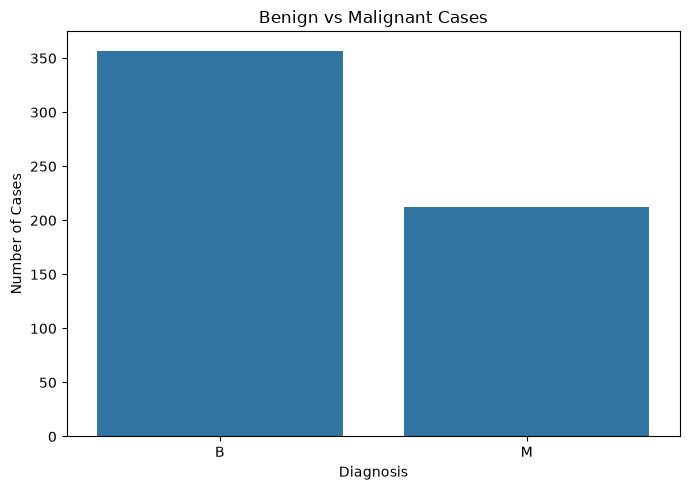

In [3]:
print("Summary statistics:")
display(df.describe().T)

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

print("\nDiagnosis distribution percentage:")
display(
    df["diagnosis"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
)

class_distribution = df["diagnosis"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("Benign vs Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "class_distribution.png"
    ),
    dpi=300
)

plt.show()

Outlier analysis:


,Feature,Outlier_Count,Lower_Bound,Upper_Bound
13,area_se,65,-23.160000,86.200000
10,radius_se,38,-0.137350,0.848650
12,perimeter_se,38,-1.020500,5.983500
23,area_worst,35,-337.750000,1937.050000
14,smoothness_se,30,0.000703,0.012612
15,compactness_se,28,-0.015975,0.061505
19,fractal_dimension_se,28,-0.001217,0.008023
18,symmetry_se,27,0.002680,0.035960
3,area_mean,25,-123.300000,1326.300000
29,fractal_dimension_worst,24,0.040530,0.123010


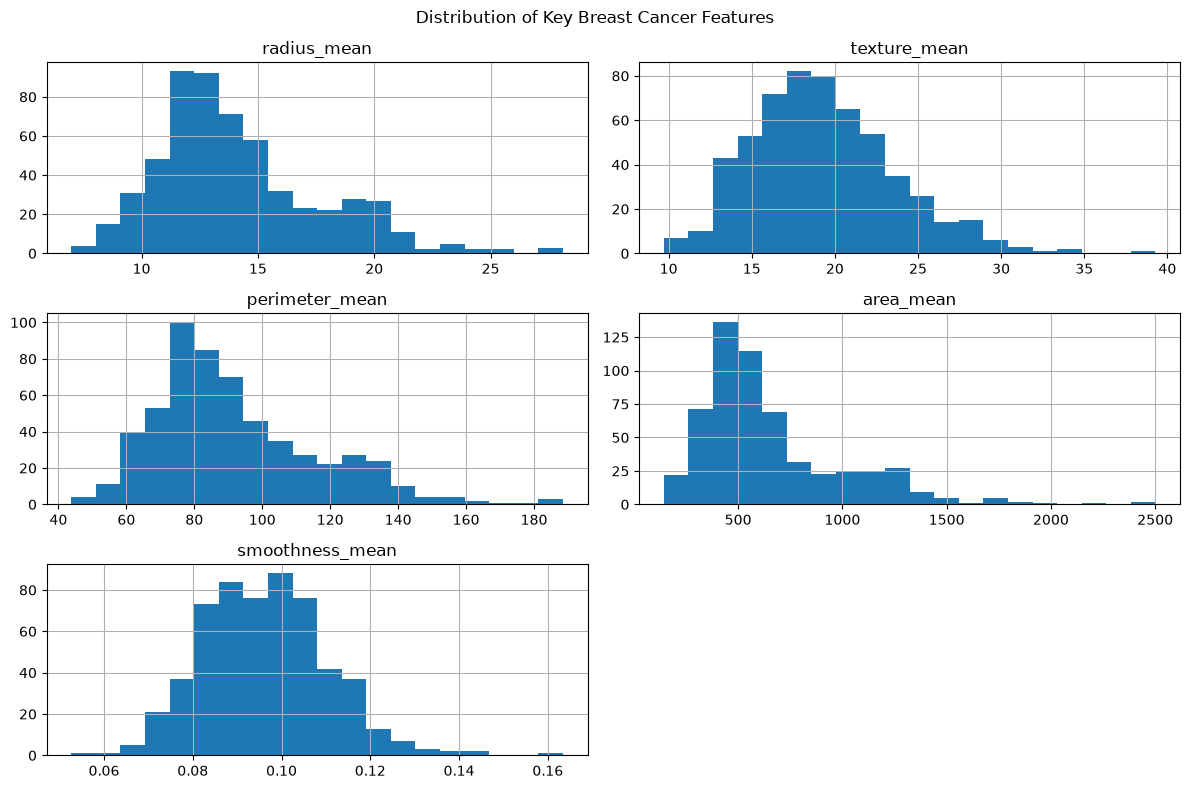

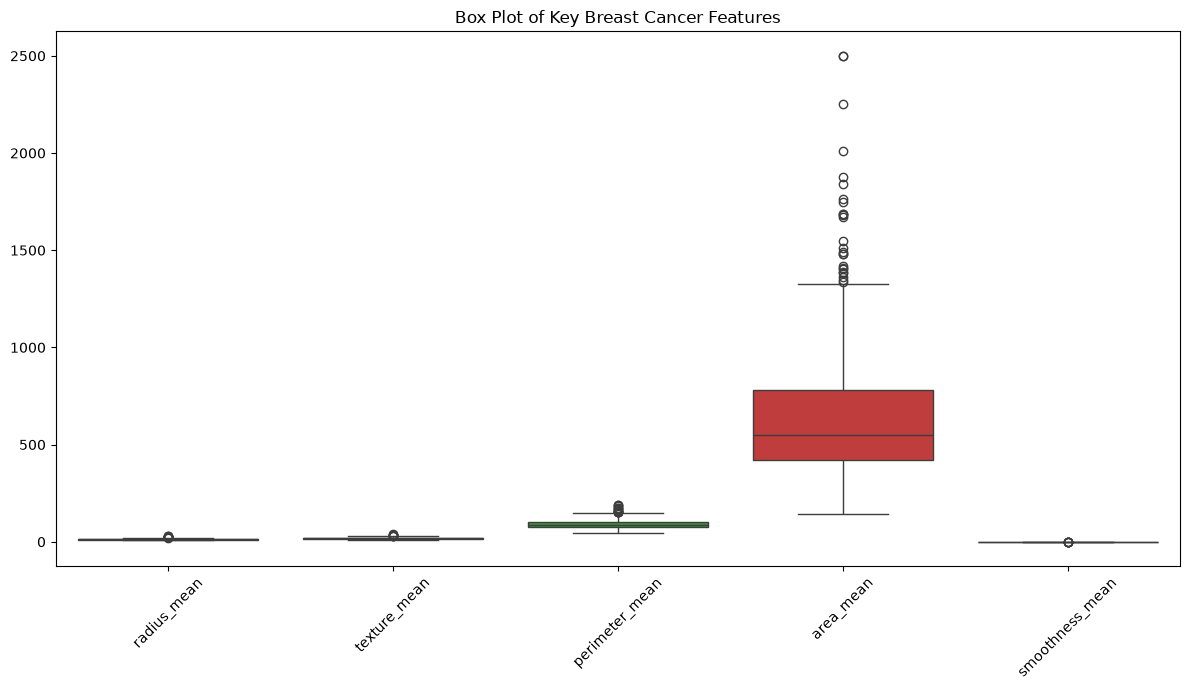

In [4]:
numeric_features = df.select_dtypes(
    include=np.number
).columns.drop("id")

outlier_summary = []

for column in numeric_features:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append([
        column,
        outlier_count,
        lower_bound,
        upper_bound
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Outlier_Count",
        "Lower_Bound",
        "Upper_Bound"
    ]
)

print("Outlier analysis:")
display(
    outlier_df.sort_values(
        "Outlier_Count",
        ascending=False
    )
)

key_features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean"
]

df[key_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle(
    "Distribution of Key Breast Cancer Features"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "feature_histograms.png"
    ),
    dpi=300
)

plt.show()

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df[key_features]
)

plt.title(
    "Box Plot of Key Breast Cancer Features"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "feature_boxplots.png"
    ),
    dpi=300
)

plt.show()

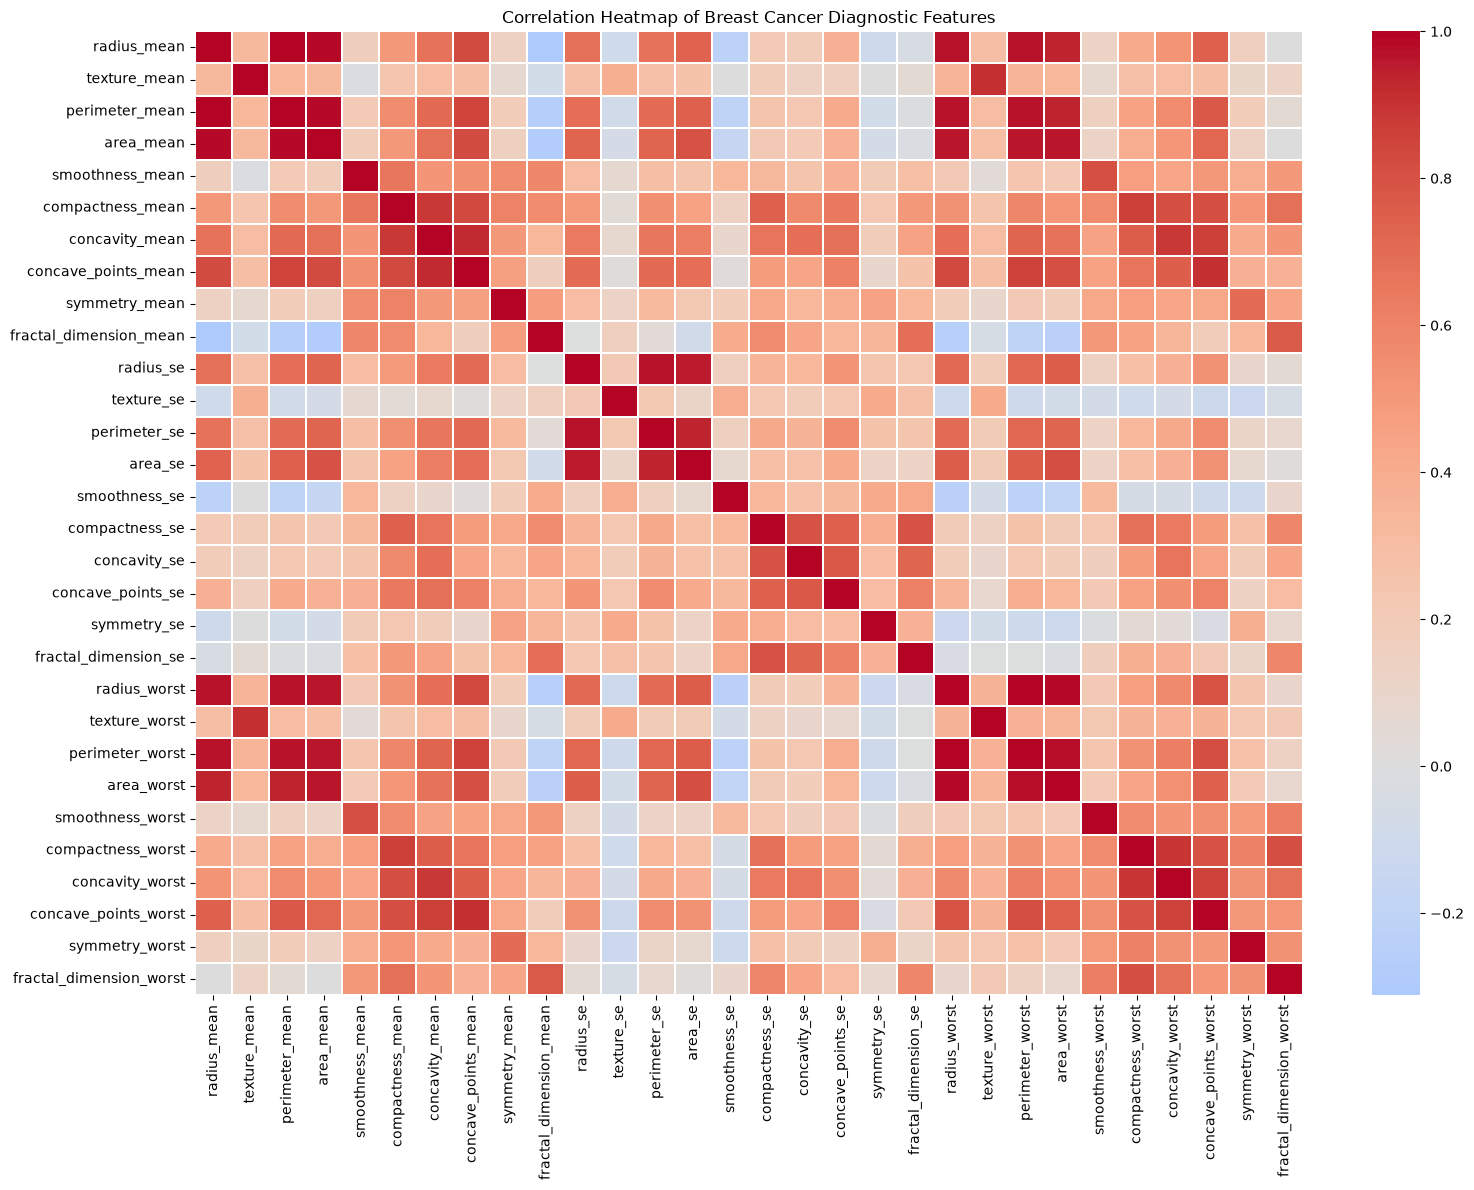

In [5]:
correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title(
    "Correlation Heatmap of Breast Cancer Diagnostic Features"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "correlation_heatmap.png"
    ),
    dpi=300
)

plt.show()

In [6]:
df["diagnosis_binary"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Encoded diagnosis distribution:")
print(df["diagnosis_binary"].value_counts())

X = df.drop(
    columns=[
        "id",
        "diagnosis",
        "diagnosis_binary"
    ]
)

y = df["diagnosis_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set shape:")
print(X_train.shape)

print("\nTesting set shape:")
print(X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Encoded diagnosis distribution:
diagnosis_binary
0    357
1    212
Name: count, dtype: int64

Training set shape:
(455, 30)

Testing set shape:
(114, 30)

Training class distribution:
diagnosis_binary
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
diagnosis_binary
0    72
1    42
Name: count, dtype: int64


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("Original training data shape:")
print(X_train.shape)

print("\nScaled training data shape:")
print(X_train_scaled.shape)

print("\nFirst 5 standardized training records:")
print(X_train_scaled[:5])

print("\nMean of standardized training features:")
print(np.mean(X_train_scaled, axis=0)[:5])

print("\nStandard deviation of standardized training features:")
print(np.std(X_train_scaled, axis=0)[:5])

Original training data shape:
(455, 30)

Scaled training data shape:
(455, 30)

First 5 standardized training records:
[[ 5.18558727e-01  8.91825791e-01  4.24631702e-01  3.83925436e-01
  -9.74743706e-01 -6.89771505e-01 -6.88586446e-01 -3.98175254e-01
  -1.03915470e+00 -8.25056321e-01 -1.09317755e-01 -5.59755400e-02
  -2.10096206e-01 -1.59132582e-02 -1.00518399e+00 -9.11941990e-01
  -6.62815884e-01 -6.52561081e-01 -7.01889114e-01 -2.75393571e-01
   5.79797697e-01  1.31324246e+00  4.66908134e-01  4.45982711e-01
  -5.96154777e-01 -6.34722227e-01 -6.10227299e-01 -2.35743918e-01
   5.45663235e-02  2.18367276e-02]
 [-5.16364088e-01 -1.63971029e+00 -5.41348716e-01 -5.42961327e-01
   4.76219058e-01 -6.31833818e-01 -6.04281166e-01 -3.03074908e-01
   5.21543093e-01 -4.54522896e-01 -6.04377961e-01 -1.00104604e+00
  -5.85429002e-01 -4.93453793e-01  4.03212009e-01 -7.68173276e-01
  -4.79187222e-01  1.14508478e-01 -1.42950761e-01 -5.77397732e-01
  -5.82458953e-01 -1.69029101e+00 -6.11934288e-01 -5.8

In [8]:
logistic_model = LogisticRegression(
    max_iter=5000,
    solver="liblinear",
    C=1.0
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred = logistic_model.predict(
    X_test_scaled
)

y_probability = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Logistic Regression model trained successfully.")

print("\nNumber of training samples:")
print(len(X_train))

print("\nNumber of testing samples:")
print(len(X_test))

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 malignant probabilities:")
print(y_probability[:10])


Logistic Regression model trained successfully.

Number of training samples:
455

Number of testing samples:
114

First 10 predicted classes:
[0 1 0 1 1 0 1 0 0 0]

First 10 malignant probabilities:
[3.74820545e-04 9.99999991e-01 4.30021162e-02 5.79925780e-01
 5.11325986e-01 6.49703777e-04 7.63374241e-01 1.02652622e-03
 5.95615737e-04 1.10147345e-02]


In [9]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("LOGISTIC REGRESSION PERFORMANCE")

print("\nAccuracy:")
print(f"{accuracy:.4f}")

print("\nPrecision:")
print(f"{precision:.4f}")

print("\nRecall:")
print(f"{recall:.4f}")

print("\nF1-score:")
print(f"{f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Benign",
            "Malignant"
        ],
        digits=4
    )
)

LOGISTIC REGRESSION PERFORMANCE

Accuracy:
0.9737

Precision:
0.9756

Recall:
0.9524

F1-score:
0.9639

Classification Report:
              precision    recall  f1-score   support

      Benign     0.9726    0.9861    0.9793        72
   Malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114



Confusion Matrix:
[[71  1]
 [ 2 40]]


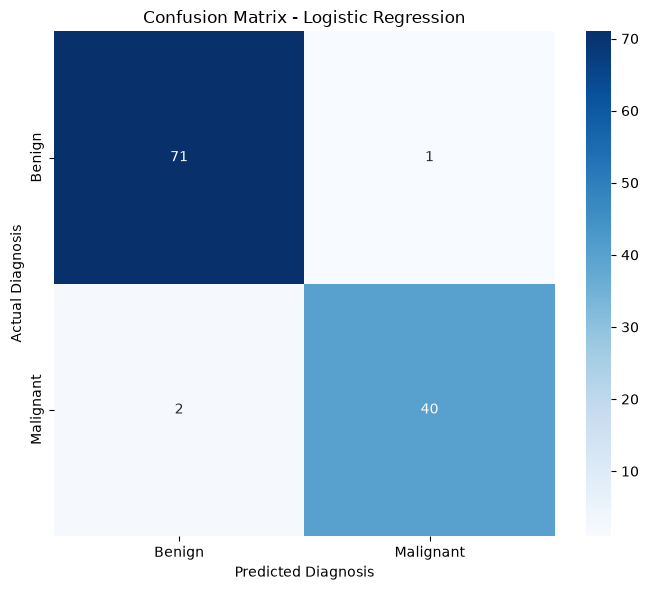

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Benign",
        "Malignant"
    ],
    yticklabels=[
        "Benign",
        "Malignant"
    ]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrix.png"
    ),
    dpi=300
)

plt.show()


ROC-AUC Score:
0.9960


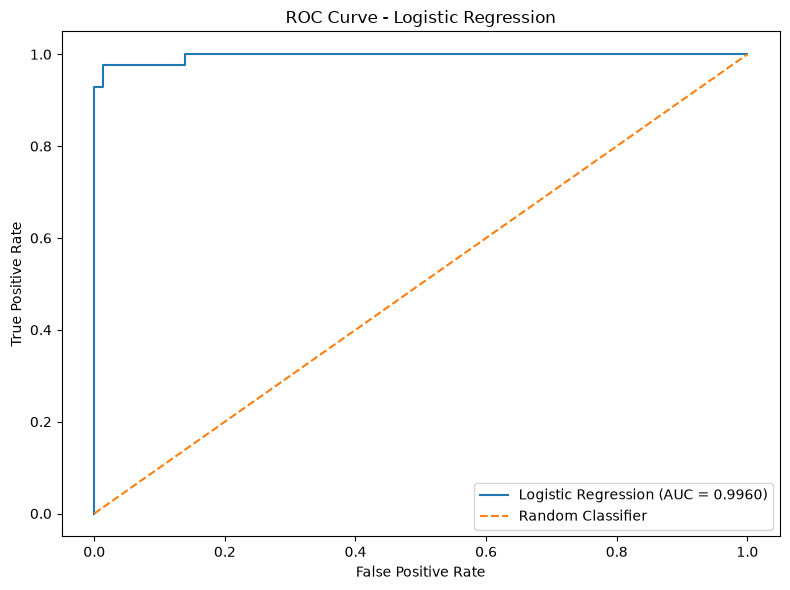

In [11]:
y_probability = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

auc_score = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC Score:")
print(f"{auc_score:.4f}")

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "roc_curve.png"
    ),
    dpi=300
)

plt.show()

In [12]:
regularization_results = []

c_values = [
    0.01,
    0.1,
    1,
    10,
    100
]

for c_value in c_values:

    regularized_model = LogisticRegression(
        C=c_value,
        max_iter=5000,
        solver="liblinear"
    )

    regularized_model.fit(
        X_train_scaled,
        y_train
    )

    predictions = regularized_model.predict(
        X_test_scaled
    )

    probabilities = regularized_model.predict_proba(
        X_test_scaled
    )[:, 1]

    regularization_results.append({
        "C": c_value,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1-Score": f1_score(
            y_test,
            predictions
        ),
        "AUC": roc_auc_score(
            y_test,
            probabilities
        )
    })

regularization_df = pd.DataFrame(
    regularization_results
)

display(
    regularization_df.round(4)
)

regularization_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "regularization_comparison.csv"
    ),
    index=False
)

,C,Accuracy,Precision,Recall,F1-Score,AUC
0,0.01,0.9649,0.9750,0.9286,0.9512,0.9980
1,0.10,0.9825,1.0000,0.9524,0.9756,0.9977
2,1.00,0.9737,0.9756,0.9524,0.9639,0.9960
3,10.00,0.9737,0.9756,0.9524,0.9639,0.9858
4,100.00,0.9474,0.9737,0.8810,0.9250,0.9769


Top 15 features by absolute coefficient:


,Feature,Coefficient,Absolute_Coefficient
21,texture_worst,1.4238,1.4238
10,radius_se,1.2436,1.2436
28,symmetry_worst,1.0591,1.0591
7,concave_points_mean,0.9548,0.9548
13,area_se,0.9334,0.9334
23,area_worst,0.9241,0.9241
15,compactness_se,-0.9158,0.9158
26,concavity_worst,0.9106,0.9106
20,radius_worst,0.8966,0.8966
6,concavity_mean,0.7905,0.7905


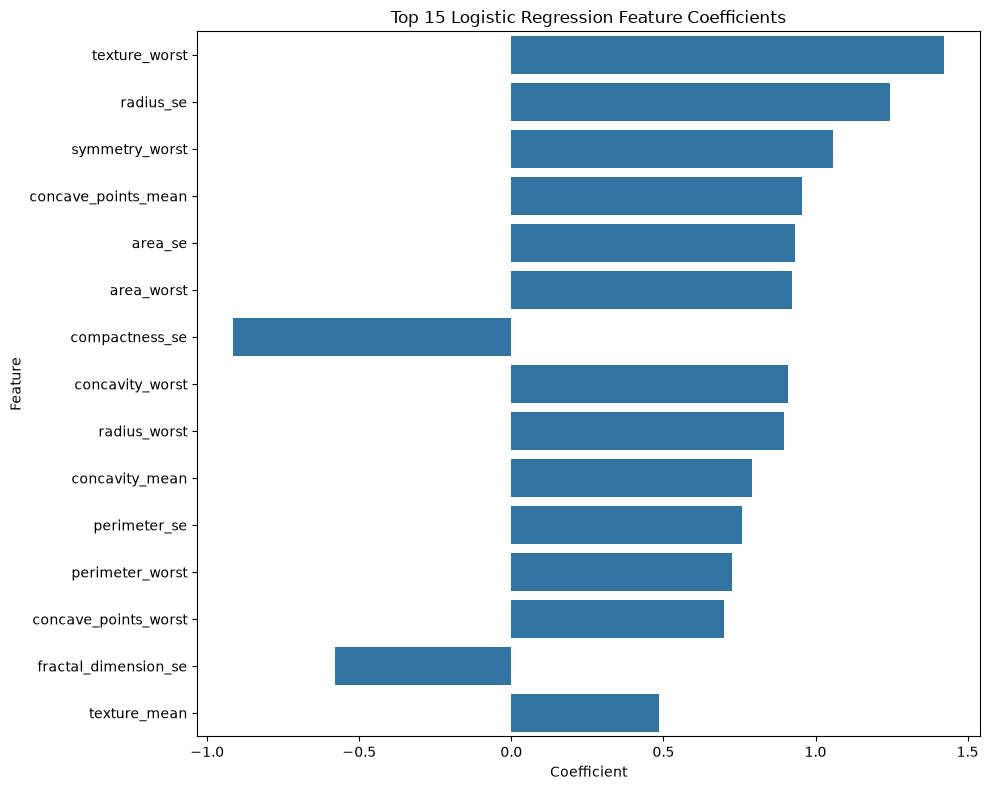

In [13]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("Top 15 features by absolute coefficient:")
display(
    coefficients.head(15).round(4)
)

top_features = coefficients.head(15)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title(
    "Top 15 Logistic Regression Feature Coefficients"
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "feature_coefficients.png"
    ),
    dpi=300
)

plt.show()

In [14]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})

display(
    final_results.round(4)
)

print("Final Logistic Regression model evaluation completed.")

,Metric,Score
0,Accuracy,0.9737
1,Precision,0.9756
2,Recall,0.9524
3,F1-Score,0.9639
4,ROC-AUC,0.9960


Final Logistic Regression model evaluation completed.


In [15]:
processed_file = os.path.join(
    DATA_DIR,
    "processed_breast_cancer.csv"
)

df.to_csv(
    processed_file,
    index=False
)

print("Processed dataset saved at:")
print(processed_file)

print("\nGenerated output files:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(file)

print("\nFinal validation:")
print(
    "Total missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Final dataset shape:",
    df.shape
)

print("\nLAB 4 - LOGISTIC REGRESSION COMPLETED")

Processed dataset saved at:
/Users/akshitgulati/Downloads/AI IN HEALTHCARE/Lab_Experiment_4/data/processed_breast_cancer.csv

Generated output files:
class_distribution.png
confusion_matrix.png
correlation_heatmap.png
feature_boxplots.png
feature_coefficients.png
feature_histograms.png
regularization_comparison.csv
roc_curve.png

Final validation:
Total missing values: 0
Duplicate rows: 0
Final dataset shape: (569, 33)

LAB 4 - LOGISTIC REGRESSION COMPLETED
